# Лабораторна робота № 7
## Діагностика моделей: відхилення, дисперсія, розбіжність даних і пріоритизація помилок

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали · лекції 9–10

---

### Постановка

Ви — аналітик сервісу, який читає рукописні цифри з бланків. Перші моделі навчали на
**сканах**: 20 000 чітких цифр. Тепер клієнти надсилають **фото з телефона**, і модель на них
помиляється значно частіше. У кожного варіанта — свій «телефон»: свої вади зйомки, яких вам
ніхто не опише.

Попередній аналітик залишив **виробничу модель** і пішов. Вам треба:

1. **поставити діагноз** виробничій моделі: відхилення, дисперсія чи розбіжність даних;
2. **знайти і впорядкувати за впливом** причини помилок на телефонних фото;
3. **скласти план дій** з обмеженим бюджетом і перевірити його числами.

> **Головне правило лабораторної.** Кожне твердження у звіті підкріплюється числом, яке ви
> отримали в цьому ноутбуці. «Модель перенавчилась» без двох похибок поруч — не діагноз.

| Частина | Що робите | Бали |
|---|---|---|
| 1 | відхилення і дисперсія: чотири вибірки, людський рівень, криві навчання, дії | 1,5 |
| 2 | різні розподіли: розклад похибки, аналіз 100 помилок, ліки з бюджетом, план, аналіз за частинами, критика звіту колеги | 2,0 |
| 3 | звіт і декларація про використання ШІ | 0,5 |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [11]:
STUDENT_NAME = 'Лящук Соломія'
LIST_NUMBER  = 6


In [12]:
assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
print('варіант', VARIANT)

варіант 6


> Поряд із ноутбуком має лежати тека `дані/` з файлами `скани.npz`,
> `lr7_варіанти_студенту.json` і **файлом вашого варіанта** `lr7_варіант_NN.npz`
> (кожен варіант — окремий файл близько 5 МБ; завантажте свій із ВНС).

In [13]:
import importlib.util, subprocess, sys
REQUIRED = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']
MODNAME = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [14]:
import warnings; warnings.filterwarnings('ignore')
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

DATA_DIR = 'дані'
C1, C2, C3, C4, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#c0392b', '#8a8a8a'
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__)

scikit-learn 1.6.1 | numpy 2.0.2


### Допоміжні функції

Їх не треба змінювати — лише розуміти, що вони роблять. Опис кожної — у рядку документації.

In [15]:
import numpy as np
from scipy import ndimage as ndi


def flat(X):
    """Зображення uint8 (n, 28, 28) → ознаки у [0, 1], форма (n, 784)."""
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


def split_train_dev(n, n_dev, seed=7):
    """Індекси навчальної частини і навчально-валідаційної вибірки (training dev set)."""
    perm = np.random.default_rng(seed).permutation(n)
    return perm[n_dev:], perm[:n_dev]


def _rotate(im, deg):
    t = np.deg2rad(deg); mat = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    c = np.array(im.shape) / 2 - 0.5
    return ndi.affine_transform(im, mat, offset=c - mat @ c, order=1, mode='constant', cval=0.0)


def distort(X, seed, angle=None, blur=None, lowres=None, background=None, contrast=None, glare=None, noise=None, share=1.0):
    """Синтез «телефонних» фото з чистих цифр. Кожен параметр — пара (від, до), з якої
    для кожного зображення береться випадкове значення; None — властивість вимкнено.
    share — частка зображень, до яких застосовують задані властивості (решта лишається чистою).
      angle      — кут повороту, градуси (знак обирається випадково)
      blur       — сигма гаусового розмиття, пікселі
      lowres     — до якої роздільності стиснути і розтягнути назад, пікселі (наприклад, (9, 12))
      background — яскравість фону, 0..1;  contrast — множник яскравості штрихів, 0..1
      glare      — сила відблиску (пляма, у якій штрихи «вигорають» до кольору фону), 0..1
      noise      — стандартне відхилення шуму сенсора
    Повертає uint8 (n, 28, 28)."""
    rng = np.random.default_rng(seed); out = np.empty(X.shape, np.float32)
    yy, xx = np.mgrid[0:28, 0:28]
    u = lambda r: rng.uniform(*r)
    for k, im in enumerate(X.astype(np.float32) / 255):
        if rng.random() < share:
            if angle: im = _rotate(im, rng.choice([-1, 1]) * u(angle))
            if blur: im = ndi.gaussian_filter(im, u(blur))
            if lowres:
                L = int(round(u(lowres))); im = ndi.zoom(ndi.zoom(im, L / 28, order=1), 28 / L, order=1)[:28, :28]
            bg = u(background) if background else 0.0
            im = bg + (u(contrast) if contrast else 1.0) * im
            if glare:
                cy, cx = rng.uniform(8, 20, 2); sg = rng.uniform(3.5, 6.5)
                w = u(glare) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sg * sg)); im = im * (1 - w) + w * bg
            if noise: im = im + rng.normal(0, u(noise), im.shape)
        out[k] = np.clip(im, 0, 1)
    return (out * 255).round().astype(np.uint8)


def image_stats(X):
    """Прості вимірювання кожного фото за пікселями — ними можна відбирати фото без міток."""
    rows = []
    yy, xx = np.mgrid[0:28, 0:28]
    for im in X.astype(np.float32) / 255:
        p50, p99 = np.percentile(im, [50, 99]); ink = np.clip(im - p50, 0, None); m = ink.sum() + 1e-9
        cy, cx = (ink * yy).sum() / m, (ink * xx).sum() / m
        mu20, mu02, mu11 = (ink * (xx - cx) ** 2).sum() / m, (ink * (yy - cy) ** 2).sum() / m, (ink * (xx - cx) * (yy - cy)).sum() / m
        rows.append({'контраст': p99 - p50,
                     'різкість': float(ndi.laplace(ndi.gaussian_filter(im, 0.5)).var()),
                     'нахил_осі': float(np.degrees(0.5 * np.arctan2(2 * mu11, mu02 - mu20))),
                     'шум': float((im - ndi.median_filter(im, 3)).std()),
                     'частка_чорнила': float((im > p50 + 0.5 * (p99 - p50)).mean())})
    return rows


def make_canvas(photos, seed, blobs=(1, 3), lines=0):
    """Полотна 56×56: телефонне фото цифри в довільному місці; плями-завади поза цифрою
    і (за потреби) lines горизонтальних ліній бланка. Повертає полотна (float 0..1) і справжні положення."""
    r = np.random.default_rng(seed); n = len(photos)
    X = np.clip(0.1 + r.normal(0, 0.04, (n, 56, 56)), 0, 1).astype(np.float32); pos = np.zeros((n, 2), int)
    yy, xx = np.mgrid[0:56, 0:56]
    for i in range(n):
        rr, cc = r.integers(0, 29, 2); pos[i] = (rr, cc)
        X[i, rr:rr + 28, cc:cc + 28] = np.maximum(X[i, rr:rr + 28, cc:cc + 28], photos[i].astype(np.float32) / 255)
        for _ in range(r.integers(blobs[0], blobs[1] + 1)):
            while True:
                br, bc = r.integers(2, 54, 2)
                if not (rr - 3 <= br <= rr + 30 and cc - 3 <= bc <= cc + 30):
                    break
            s, a = r.uniform(1.2, 2.2), r.uniform(0.5, 0.9)
            X[i] = np.maximum(X[i], 0.1 + a * np.exp(-((yy - br) ** 2 + (xx - bc) ** 2) / (2 * s * s)))
        for _ in range(lines):
            ly = r.integers(4, 52); X[i, ly:ly + 2, :] = np.maximum(X[i, ly:ly + 2, :], r.uniform(0.45, 0.7))
    return np.clip(X, 0, 1), pos


def locate(X, thr=0.3):
    """Компонент A (без навчання): лівий верхній кут вирізу 28×28 навколо цифри."""
    out = np.zeros((len(X), 2), int)
    for i, im in enumerate(X):
        ink = np.clip(ndi.gaussian_filter(im, 0.7) - thr, 0, None)
        s = ndi.uniform_filter(ink, size=28, mode='constant')[14:43, 14:43]
        r0, c0 = np.unravel_index(np.argmax(s), s.shape)
        w = ink[r0:r0 + 28, c0:c0 + 28].copy(); lab, n = ndi.label(w > 0)
        if n > 1:
            w[lab != 1 + np.argmax(ndi.sum(w, lab, range(1, n + 1)))] = 0
        m = w.sum() + 1e-9; cy = (w.sum(1) * np.arange(28)).sum() / m; cx = (w.sum(0) * np.arange(28)).sum() / m
        out[i] = (int(np.clip(round(r0 + cy - 14), 0, 28)), int(np.clip(round(c0 + cx - 14), 0, 28)))
    return out


def crop(X, pos):
    """Вирізи 28×28 у форматі uint8, як фото."""
    return (np.stack([X[i, p[0]:p[0] + 28, p[1]:p[1] + 28] for i, p in enumerate(pos)]) * 255).round().astype(np.uint8)


def shifted_copies(X, seed, k=2):
    """Копії зображень, зсунуті на випадкові ±k пікселів: класифікатор після локалізатора має їх витримувати."""
    r = np.random.default_rng(seed); out = np.empty_like(X)
    for i in range(len(X)):
        dy, dx = r.integers(-k, k + 1, 2); out[i] = np.roll(np.roll(X[i], dy, 0), dx, 1)
    return out

In [16]:
def err(model, X, y):
    """Похибка у відсотках (частка неправильних відповідей × 100)."""
    return round(100 * float((model.predict(X) != y).mean()), 2)


def show_grid(images, titles=None, ncol=10, size=1.05, title=None):
    """Сітка зображень; темне — чорнило."""
    n = len(images); nrow = (n + ncol - 1) // ncol
    fig, axs = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.35 if title else 0) + 0.25 * nrow))
    for k, ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k], cmap='gray_r', vmin=0, vmax=255 if np.asarray(images[k]).max() > 1 else 1)
            if titles:
                ax.set_title(titles[k], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


_TEST_CALLS = []


def evaluate_on_test(model, name):
    """Остаточна оцінка на тестовій вибірці. Викликайте ОДИН раз — для обраної моделі."""
    _TEST_CALLS.append(name)
    if len(_TEST_CALLS) > 1:
        print('УВАГА: тестову вибірку використано вже', len(_TEST_CALLS), 'рази — це буде видно у звіті')
    return err(model, flat(TEST_X), TEST_Y)

### Дані

| Масив | Що це | Скільки |
|---|---|---|
| `SCAN_X`, `SCAN_Y` | скани: чіткі цифри | 20 000 |
| `PHONE_X`, `PHONE_Y` | телефонні фото з мітками, для навчання | 2000 |
| `POOL_X`, `POOL_Y` | телефонні фото, які можна **докупити** (частина 2; бюджет — 1000 штук) | 2000 |
| `DEV_X`, `DEV_Y` | валідаційна вибірка: телефонні фото | 1500 |
| `TEST_X`, `TEST_Y` | тестова вибірка: телефонні фото — **лише для остаточної оцінки** | 1500 |
| `HUMAN_X` | 50 фото для вимірювання людського рівня (мітки приховано) | 50 |

Валідаційна і тестова вибірки — з того розподілу, на якому сервіс має працювати:
телефонні фото (лекція 10, розділ 36).

In [17]:
S = np.load(os.path.join(DATA_DIR, 'скани.npz'))
V = np.load(os.path.join(DATA_DIR, 'lr7_варіант_%02d.npz' % VARIANT))
with open(os.path.join(DATA_DIR, 'lr7_варіанти_студенту.json'), encoding='utf-8') as f:
    INFO = json.load(f)[VARIANT - 1]
SCAN_X, SCAN_Y = S['scan_X'], S['scan_y']
PHONE_X, PHONE_Y = V['phone_train_X'], V['phone_train_y']
POOL_X, POOL_Y = V['pool_X'], V['pool_y']
DEV_X, DEV_Y = V['dev_X'], V['dev_y']
TEST_X, TEST_Y = V['test_X'], V['test_y']
HUMAN_X, HUMAN_CODE = V['human_X'], V['human_code']
for nm in ['SCAN_X', 'PHONE_X', 'POOL_X', 'DEV_X', 'TEST_X', 'HUMAN_X']:
    print('%-8s' % nm, globals()[nm].shape)
print()
print('Виробнича модель попереднього аналітика:')
print('  навчена на:', INFO['виробнича']['навчена_на'])
print('  модель:    ', INFO['виробнича']['модель'])

SCAN_X   (20000, 28, 28)
PHONE_X  (2000, 28, 28)
POOL_X   (2000, 28, 28)
DEV_X    (1500, 28, 28)
TEST_X   (1500, 28, 28)
HUMAN_X  (50, 28, 28)

Виробнича модель попереднього аналітика:
  навчена на: скани
  модель:     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


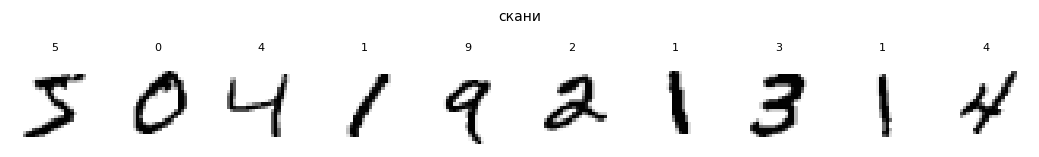

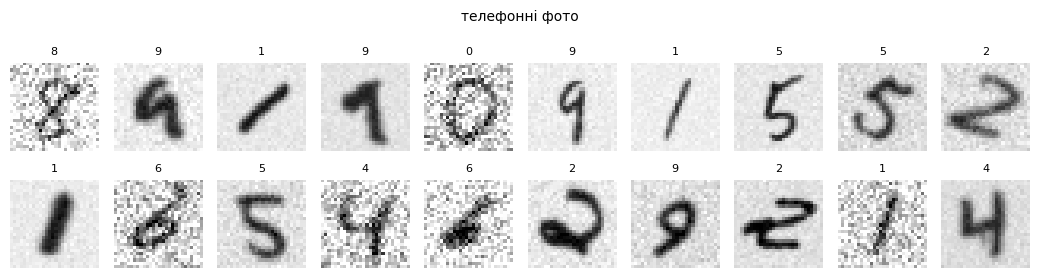

In [18]:
show_grid(SCAN_X[:10], [str(v) for v in SCAN_Y[:10]], title='скани')
show_grid(PHONE_X[:20], [str(v) for v in PHONE_Y[:20]], title='телефонні фото')

---
# Частина 1. Відхилення і дисперсія (1,5 бала)
---
## 1. Чотири вибірки

Щоб розрізнити дисперсію і розбіжність даних, потрібна **навчально-валідаційна вибірка**
(training dev set): приклади з **того самого розподілу, на якому вчилася модель**, але не
показані їй під час навчання (лекція 10, розділ 40).

Виробнича модель навчалась на джерелі, назва якого надрукована вище. Оберіть те саме
джерело і відкладіть із нього навчально-валідаційну вибірку:

| джерело | що це | скільки відкласти |
|---|---|---|
| `'скани'` | лише 20 000 сканів | 2000 |
| `'телефон'` | лише 2000 телефонних фото | 400 |
| `'суміш'` | 20 000 сканів + 2000 фото | 2000 |

### Завдання 1.1

In [19]:
TRAIN_SOURCE = 'скани'
WHY_TRAIN_DEV = 'Виробнича модель навчена лише на сканах, тож навчально-валідаційну вибірку відкладаю зі сканів: це нові приклади ТОГО САМОГО розподілу, яких модель не бачила. Різниця навч-вал − навч тоді чисто дисперсія. Якби я взяла телефонні фото, це була б уже валідаційна вибірка (інший розподіл), і розрив змішав би дисперсію з розбіжністю даних.'


In [20]:
SOURCES = {'скани': (SCAN_X, SCAN_Y), 'телефон': (PHONE_X, PHONE_Y),
           'суміш': (np.concatenate([SCAN_X, PHONE_X]), np.concatenate([SCAN_Y, PHONE_Y]))}
N_TRAIN_DEV = {'скани': 2000, 'телефон': 400, 'суміш': 2000}
assert TRAIN_SOURCE in SOURCES, 'оберіть одне з трьох джерел'
assert WHY_TRAIN_DEV, 'поясніть вибір'
SRC_X, SRC_Y = SOURCES[TRAIN_SOURCE]
idx_tr, idx_td = split_train_dev(len(SRC_Y), N_TRAIN_DEV[TRAIN_SOURCE])
X_tr, y_tr = flat(SRC_X[idx_tr]), SRC_Y[idx_tr]
X_td, y_td = flat(SRC_X[idx_td]), SRC_Y[idx_td]
X_dev, y_dev = flat(DEV_X), DEV_Y
print(f'навчальна: {len(y_tr)} | навчально-валідаційна: {len(y_td)} | валідаційна: {len(y_dev)} | тестова: {len(TEST_Y)} (не чіпаємо)')

навчальна: 18000 | навчально-валідаційна: 2000 | валідаційна: 1500 | тестова: 1500 (не чіпаємо)


> Ми взяли 2000 сканів із 20 000 для навчально-валідаційної, а решта 18 000 пішла в навчання. Вибір 'скани' правильний, бо модель вчилась на сканах. Якби ми взяли фото, дисперсія і розбіжність злились би в одне число, і ми б не знали, з чим боротись. Виробнича модель вчилась на **сканах**, тому «чесну» вибірку для дисперсії (навчально-валідаційну) відкладаємо теж зі **сканів**. Телефонні фото — це вже валідаційна: інший розподіл.

## 2. Людський рівень

Оптимальну похибку ми не знаємо, тож оцінюємо її **людським рівнем** — найкращим, якого
досягає людина на тих самих фото (лекція 10, розділи 33–34). Подивіться на 50 фото свого
варіанта і впишіть цифри підряд — 50 символів, пробіли не важливі. Не збільшуйте зображення
більше, ніж його бачить модель, і не підглядайте в мітки.

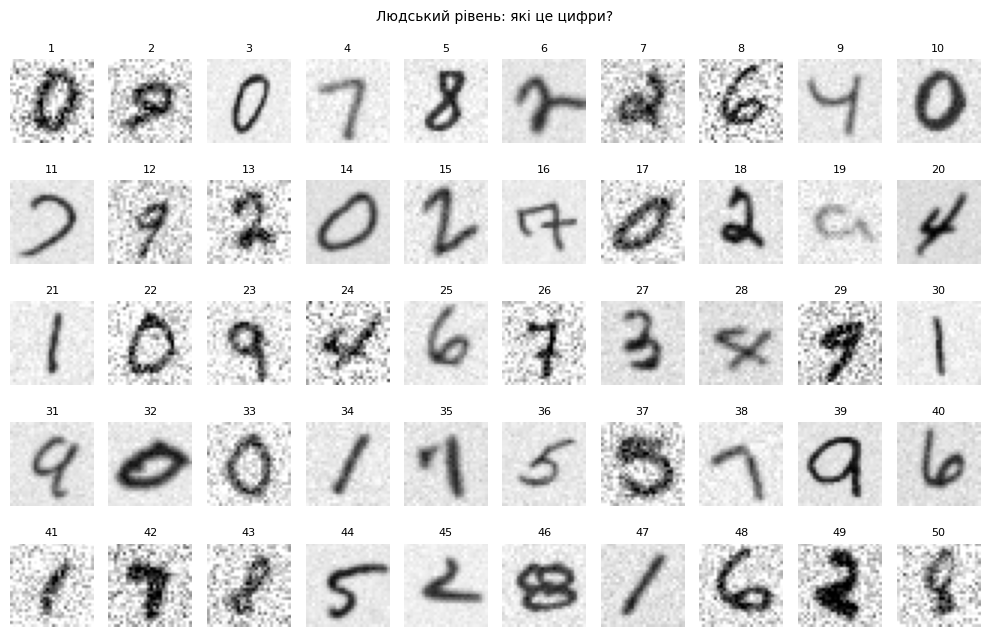

In [21]:
show_grid(HUMAN_X, [str(k + 1) for k in range(50)], size=1.0, title='Людський рівень: які це цифри?')

### Завдання 2.1

In [22]:
HUMAN_ANSWERS = '09078226409920270294109467389140017557961785281628'


In [23]:
ans = [int(c) for c in HUMAN_ANSWERS if c.isdigit()]
assert len(ans) == 50, f'потрібно 50 цифр, а введено {len(ans)}'
truth = (HUMAN_CODE - 7 * np.arange(50)) % 10
HUMAN_ERR = round(100 * float(np.mean(np.array(ans) != truth)), 1)
print('ваша похибка на 50 фото:', HUMAN_ERR, '%')
print('номери фото, де ви помилились:', [k + 1 for k in range(50) if ans[k] != truth[k]])

ваша похибка на 50 фото: 6.0 %
номери фото, де ви помилились: [11, 28, 31]


>  Людський рівень = наскільки помиляється людина на цих фото; це наближення до оптимуму. Моя похибка **6 %** (фото 11, 28, 31). Беруть **найкращий** результат, а не середній.

> **Одна помилка на 50 фото — це 2 %, і довірчий інтервал такої оцінки широкий.**
> Як людський рівень беріть найкращий результат, якого досягла людина на цих фото: якщо
> одногрупник із тим самим варіантом має менше помилок — використайте його число і
> зазначте це у звіті.

## 3. Діагноз виробничої моделі

Відтворюємо виробничу модель і рахуємо похибки на трьох вибірках. Розклад (лекція 10, розділ 41):

$$\underbrace{E_{\text{навч}} - E_{\text{людина}}}_{\text{усувне відхилення}},\qquad
\underbrace{E_{\text{навч-вал}} - E_{\text{навч}}}_{\text{дисперсія}},\qquad
\underbrace{E_{\text{вал}} - E_{\text{навч-вал}}}_{\text{розбіжність даних}}$$

In [24]:
PRODUCTION = eval(INFO['виробнича']['модель'])       
t0 = time.time()
prod = PRODUCTION.fit(X_tr, y_tr)
E_PROD = {'навч': err(prod, X_tr, y_tr), 'навч_вал': err(prod, X_td, y_td), 'вал': err(prod, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с')
print('похибки виробничої моделі, %:', E_PROD)
DECOMP_PROD = {'усувне відхилення': round(E_PROD['навч'] - HUMAN_ERR, 2),
               'дисперсія': round(E_PROD['навч_вал'] - E_PROD['навч'], 2),
               'розбіжність даних': round(E_PROD['вал'] - E_PROD['навч_вал'], 2)}
pd.Series(DECOMP_PROD, name='п. п.').to_frame()

навчено за 3 с
похибки виробничої моделі, %: {'навч': 0.0, 'навч_вал': 3.85, 'вал': 47.2}


,п. п.
усувне відхилення,-6.00
дисперсія,3.85
розбіжність даних,43.35


> Навчили виробничу модель на сканах і порахували похибку в трьох місцях: навчальна 0,0 %, навчально-валідаційна 3,85 %, валідаційна (фото) 47,4 %. З різниць виходить: відхилення 0,0 − 6,0 = −6,0 п. п. (його немає), дисперсія 3,85 − 0,0 = 3,85 п. п. (мала), розбіжність даних 47,4 − 3,85 = 43,55 п. п. (величезна). Головна проблема — розбіжність даних: модель вивчила скани, але фото з телефона для неї інший тип картинок.

### Завдання 3.1

Поставте діагноз. Якщо дві складові близькі, назвіть головну і поясніть, чому друга —
другорядна.

In [25]:
DIAGNOSIS = 'розбіжність'
DIAGNOSIS_WHY = "Навчально-валідаційна похибка 3,85 % (скани, яких модель не бачила), а валідаційна на телефонних фото 47,4 %: різниця 43,55 п. п. — це розбіжність даних. Дисперсія лише 3,85 п. п. (3,85 − 0,0), усувне відхилення від'ємне (0,0 − 6,0 = −6,0): навчальна похибка 0 %, тобто модель вивчила навчальні дані повністю."


In [26]:
assert DIAGNOSIS in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_WHY, 'заповніть діагноз і доказ'
print('діагноз:', DIAGNOSIS)

діагноз: розбіжність


> Три сходинки: навч − людина = відхилення (**−6,0**), навч-вал − навч = дисперсія (**3,85**), вал − навч-вал = розбіжність (**43,55**). Найбільша — розбіжність: модель на сканах чудова, а на фото з телефона — ні, тому головна проблема в тому, що модель вчилась на одному типі картинок, а перевіряється на іншому. На нових сканах вона помиляється лише в 3,85 % випадків, а на фото в 47,4 %. Отже, вона вміє читати чіткі скани, але не вміє читати шум і нахил із телефона.

## 4. Крива навчання

Крива навчання показує, чи допоможуть ще дані того самого розподілу.
Навчаємо виробничу модель на 10, 25, 50 і 100 % навчальної частини і дивимось на похибку на
навчальній і навчально-валідаційній вибірках; пунктиром — валідаційна похибка повної моделі
і ваш людський рівень. Це триває 1–3 хвилини.

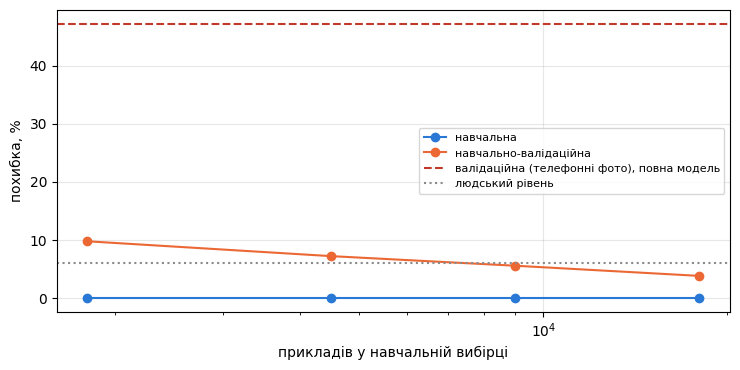

,n,навч,навч_вал
0,1800,0.0,9.80
1,4500,0.0,7.25
2,9000,0.0,5.60
3,18000,0.0,3.85


In [27]:
curve = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = max(50, int(len(y_tr) * frac))
    m = eval(INFO['виробнича']['модель']).fit(X_tr[:n], y_tr[:n])
    curve.append({'n': n, 'навч': err(m, X_tr[:n], y_tr[:n]), 'навч_вал': err(m, X_td, y_td)})
CURVE = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(CURVE['n'], CURVE['навч'], 'o-', color=C1, label='навчальна')
ax.plot(CURVE['n'], CURVE['навч_вал'], 'o-', color=C2, label='навчально-валідаційна')
ax.axhline(E_PROD['вал'], ls='--', color=C4, label='валідаційна (телефонні фото), повна модель')
ax.axhline(HUMAN_ERR, ls=':', color=GREY, label='людський рівень')
ax.set_xscale('log'); ax.set_xlabel('прикладів у навчальній вибірці'); ax.set_ylabel('похибка, %')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
CURVE

>  Навчаємо виробничу модель на 10, 25, 50 і 100 % навчальних сканів (від 1800 до 18 000) і дивимось, як міняється похибка. Синя лінія (навчальна) лежить на 0 %. Помаранчева (навчально-валідаційна) падає з 9,8 до 3,85 %, тобто більше сканів трохи зменшує дисперсію. Червона пунктирна лінія (валідаційна, фото з телефона) стоїть на 47,4 % і від кількості сканів не залежить. 

### Завдання 4.1

In [28]:
MORE_SAME_DATA_HELPS = False
CURVE_WHY = 'Навчальна крива лежить на 0 % при всіх n (1800–18 000), навчально-валідаційна падає 9,8 → 7,25 → 5,6 → 3,85 %, але валідаційна (телефон) пунктиром стоїть на 47,4 %, у десятки разів вище. Більше сканів зменшує лише малу дисперсію (≤ 3,85 п. п.) і не чіпає 43,55 п. п. розбіжності: скани не схожі на фото, потрібні дані з цільового розподілу.'


In [29]:
assert MORE_SAME_DATA_HELPS in (True, False) and CURVE_WHY, 'заповніть висновок за кривою'

> **Висновок:** більше даних того самого типу (сканів) не допоможе, бо головна проблема — розбіжність даних (розрив 43,6 п. п.), а не нестача сканів. Модель навчили на одну типі фото а працює вона на іншому

## 5. Дії: що допомагає, а що — ні

Таблиці лекції 9 (розділи 25 і 27) кажуть, які дії зменшують відхилення, а які — дисперсію;
лекція 10 (розділи 37–43) — що робити з розбіжністю. Перевірте це на своїй моделі:

* **дві дії**, які, за вашим діагнозом, мають допомогти;
* **одну контрольну дію**, спрямовану на **іншу** проблему, — вона допомогти не повинна.

Кожна дія — це модель і навчальні дані. Похибки рахуються на тих самих навчально-валідаційній
і валідаційній вибірках, що й у пункті 3. Готові «цеглинки»:
`X_tr, y_tr` — навчальна частина вашого джерела; `flat(SCAN_X), SCAN_Y` — усі скани;
`flat(PHONE_X), PHONE_Y` — усі телефонні фото (увага: частина з них — у навчально-валідаційній
вибірці, якщо джерело `'телефон'` чи `'суміш'`; використовуйте `X_tr` і додавайте до нього
лише те, чого в ній немає); `SRC_X[idx_tr]` — ті самі навчальні приклади як зображення, з яких
`shifted_copies(SRC_X[idx_tr], seed, k)` робить копії, зсунуті на ±k пікселів (аугментація);
`distort(...)` — синтез «телефонних» фото (опис — у розділі 8).

Приклад запису:

```python
('більша модель: MLP(256)', 'відхилення',
 MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0), X_tr, y_tr)
```

Одна дія навчається від кількох секунд до хвилини.

In [30]:
SYN_A = dict(angle=(5, 25), blur=(0.3, 0.9), background=(0.06, 0.18), contrast=(0.65, 0.9), noise=(0.03, 0.17))
SYN_A_X = flat(distort(SRC_X[idx_tr], seed=3, share=1.0, **SYN_A))
ACTIONS = [
    ('+2000 справжніх телефонних фото в навчання', 'розбіжність даних',
     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0),
     np.concatenate([X_tr, flat(PHONE_X)]), np.concatenate([y_tr, PHONE_Y])),
    ('+18 000 синтетичних «телефонних» копій сканів (distort)', 'розбіжність даних',
     MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0),
     np.concatenate([X_tr, SYN_A_X]), np.concatenate([y_tr, y_tr])),
    ('контрольна: більша модель MLP(512, 256)', 'усувне відхилення',
     MLPClassifier(hidden_layer_sizes=(512, 256), max_iter=30, random_state=0), X_tr, y_tr),
]


In [31]:
assert len(ACTIONS) >= 3, 'потрібно щонайменше три дії: дві за діагнозом і одна контрольна'
rows = [{'дія': 'виробнича модель (до змін)', 'на що спрямована': '—', **E_PROD}]
for name, target, model, Xa, ya in ACTIONS:
    t0 = time.time(); model.fit(Xa, ya)
    rows.append({'дія': name, 'на що спрямована': target, 'навч': err(model, Xa, ya),
                 'навч_вал': err(model, X_td, y_td), 'вал': err(model, X_dev, y_dev)})
    print(f'{name}: {time.time() - t0:.0f} с')
ACT_TABLE = pd.DataFrame(rows)
ACT_TABLE['Δ дисперсії, п. п.'] = (ACT_TABLE['навч_вал'] - ACT_TABLE['навч']) - (E_PROD['навч_вал'] - E_PROD['навч'])
ACT_TABLE['Δ відхилення, п. п.'] = ACT_TABLE['навч'] - E_PROD['навч']
ACT_TABLE['Δ валідаційної, п. п.'] = ACT_TABLE['вал'] - E_PROD['вал']
ACT_TABLE.round(2)

+2000 справжніх телефонних фото в навчання: 3 с
+18 000 синтетичних «телефонних» копій сканів (distort): 5 с
контрольна: більша модель MLP(512, 256): 6 с


,дія,на що спрямована,навч,навч_вал,вал,"Δ дисперсії, п. п.","Δ відхилення, п. п.","Δ валідаційної, п. п."
0,виробнича модель (до змін),—,0.0,3.85,47.20,0.0,0.0,0.00
1,+2000 справжніх телефонних фото в навчання,розбіжність даних,0.0,3.55,9.13,-0.3,0.0,-38.07
2,+18 000 синтетичних «телефонних» копій сканів (distort),розбіжність даних,0.0,2.95,5.80,-0.9,0.0,-41.40
3,"контрольна: більша модель MLP(512, 256)",усувне відхилення,0.0,3.25,34.87,-0.6,0.0,-12.33


> Перевіряємо, кожне навчаємо наново на виробничій моделі. Дві дії спрямовані на розбіжність даних: **+2000 справжніх фото** в навчання і **+18 000 синтетичних «телефонних» копій сканів** (функція `distort`). Третя дія контрольна: **більша мережа 512×256**, яка лікує усувне відхилення, якого в нас нема, тому вона не повинна допомогти. 

Результат (валідаційна похибка, була 47,4 %): справжні фото → **9,07 %** (−38,33 п. п.), синтетичні → **5,87 %** (−41,53 п. п.), більша мережа → **35,53 %** (−11,87 п. п.).

### Завдання 5.1

In [32]:
ACTIONS_CONCLUSION = 'Допомогли обидві дії проти розбіжності: +2000 справжніх фото в навчання зменшили валідаційну похибку 47,4 → 9,07 % (−38,33 п. п.), +18 000 синтетичних копій сканів (distort) — до 5,87 % (−41,53 п. п.); дисперсія майже не змінилась (−0,35 і −1,10 п. п.). Контрольна дія (більша мережа 512×256, спрямована на відхилення) відхилення не змінила (навчальна 0 % → 0 %, Δ = 0), але валідаційну знизила 47,4 → 35,53 % (−11,87 п. п.). Прогноз «не допоможе» справдився лише наполовину: вона допомогла несподівано, але набагато слабше (35,5 % проти 5,9–9,1 %), і розбіжність лишилась ≈ 32 п. п. Я перевірила на трьох зернах: 256 — 45,3–47,4 %, 512×256 — 34,7–41,0 %, тобто ефект не випадковий (ширша мережа на сканах трохи стійкіша до шуму), але діагноз це не змінює: головна проблема — розбіжність, і лікують її даними, схожими на фото.'


In [33]:
assert ACTIONS_CONCLUSION, 'сформулюйте висновок'

>  Проти розбіжності допомагають дані, схожі на фото: **+2000 справжніх фото → 9,07 %**, **+синтетичні → 5,87 %**. Контрольна дія (більша мережа) допомогла лише частково (35,5 %), розбіжність лишилась ≈ 32 п. п.

---
# Частина 2. Різні розподіли і пріоритизація помилок (2,0 бала)
---
## 6. Модель B і розклад її похибки

Далі працюємо з моделлю, яку радить лекція 10 (розділ 37): велика мережа на **суміші** сканів і
телефонних фото. Навчально-валідаційна вибірка — 2000 прикладів суміші.

навчено за 3 с; похибки моделі B, %: {'навч': 0.0, 'навч_вал': 3.7, 'вал': 8.87}


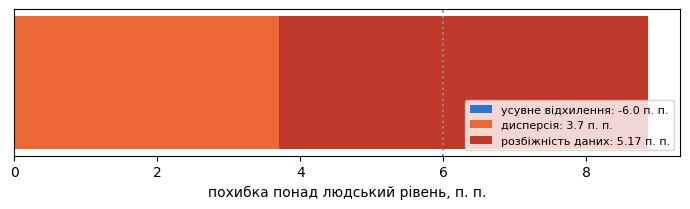

In [34]:
MIX_X, MIX_Y = SOURCES['суміш']
mix_tr, mix_td = split_train_dev(len(MIX_Y), 2000)
XB_tr, yB_tr = flat(MIX_X[mix_tr]), MIX_Y[mix_tr]
XB_td, yB_td = flat(MIX_X[mix_td]), MIX_Y[mix_td]


def model_b():
    return MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


t0 = time.time()
B = model_b().fit(XB_tr, yB_tr)
pred_B = B.predict(X_dev)
E_B = {'навч': err(B, XB_tr, yB_tr), 'навч_вал': err(B, XB_td, yB_td), 'вал': err(B, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с; похибки моделі B, %:', E_B)
DECOMP_B = {'усувне відхилення': round(E_B['навч'] - HUMAN_ERR, 2), 'дисперсія': round(E_B['навч_вал'] - E_B['навч'], 2),
            'розбіжність даних': round(E_B['вал'] - E_B['навч_вал'], 2)}
fig, ax = plt.subplots(figsize=(7, 2.2))
left = 0
for (k, v), c in zip(DECOMP_B.items(), [C1, C2, C4]):
    ax.barh(0, max(v, 0), left=left, color=c, label=f'{k}: {v} п. п.'); left += max(v, 0)
ax.axvline(HUMAN_ERR, color=GREY, ls=':'); ax.set_yticks([]); ax.set_xlabel('похибка понад людський рівень, п. п.')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### Завдання 6.1

In [35]:
DIAGNOSIS_B = 'розбіжність'
DIAGNOSIS_B_WHY = 'Модель B: навчальна 0,0 %, навчально-валідаційна 3,7 %, валідаційна 8,8 %. Розклад: відхилення −6,0 (людина 6 %, навчальна 0 %), дисперсія 3,7 п. п., розбіжність 8,8 − 3,7 = 5,1 п. п. Головна складова — розбіжність (5,1 > 3,7), хоча дисперсія теж помітна. Більше сканів не допоможе: у суміші вже 20 000 сканів проти 2000 фото, скани лише зменшили б дисперсію на сканоподібній навчально-валідаційній вибірці, а 5,1 п. п. — це різниця між розподілом навчання і телефонними фото.'


In [36]:
assert DIAGNOSIS_B in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_B_WHY

>  Модель B: розбіжність 5,1 п. п. > дисперсія 3,7 п. п. Тут розбіжність головна, але вже не така величезна, бо в навчанні є 2000 справжніх фото.

## 7. Аналіз 100 помилок

Метод лекції 9 (розділи 14–19) і лекції 10 (розділ 42): переглянути помилки **очима**,
позначити, що з кожним фото не так, і порахувати, скільки дасть усунення кожної причини.

Нижче — перші 100 помилок моделі B на валідаційній вибірці (у порядку номерів фото). Над
кожним фото: порядковий номер помилки, **мітка → прогноз моделі**.

**Словник категорій** (можна кілька через `+`):

| категорія | як виглядає |
|---|---|
| `нахил` | цифра помітно повернута |
| `розмиття` | штрихи розмиті, краї нечіткі |
| `низька роздільність` | «сходинки», цифра наче з кількох великих пікселів |
| `тьмяність` | сірий фон, блідий слабкий штрих |
| `відблиск` | частина штриха «вигоріла» до кольору фону |
| `шум` | зерно, крапки по всьому фото |
| `хибна мітка:N` | модель, схоже, права, а мітка хибна; N — правильна, на вашу думку, цифра |
| `нерозбірливо` | людина теж не впевнена |
| `інше` | нічого з переліченого |

Приклад: `'нахил+шум'`, `'хибна мітка:4'`, `'інше'`.

помилок моделі B на валідаційній вибірці: 133 | переглядаємо: 100


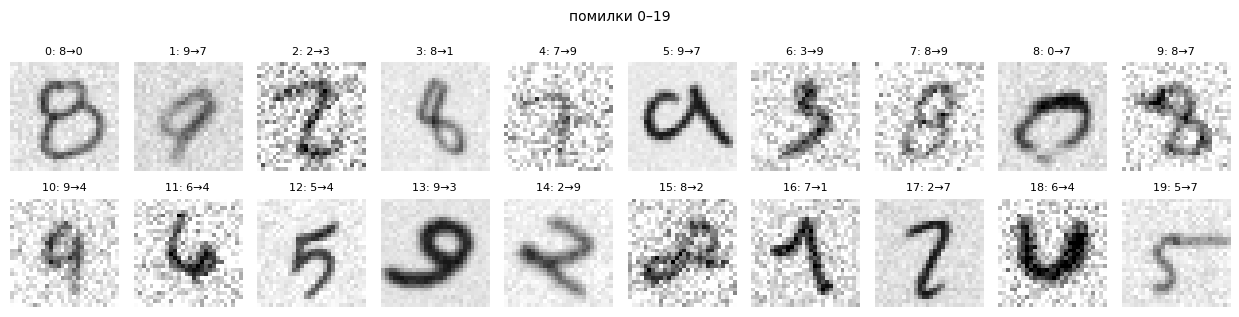

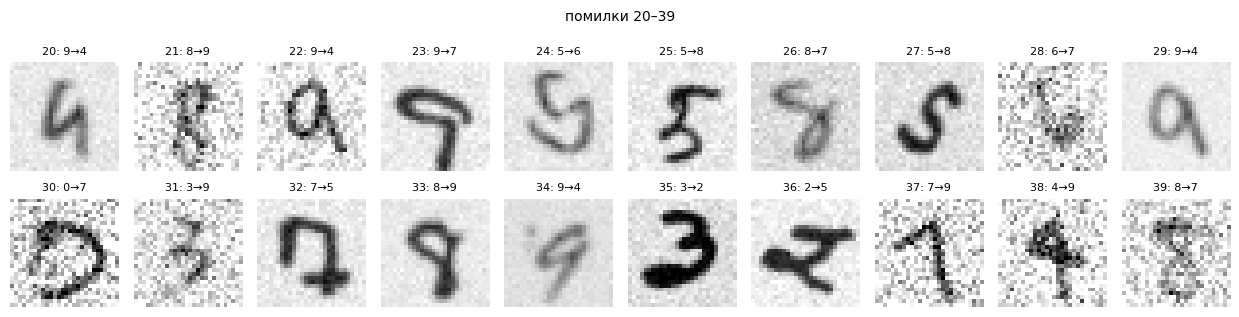

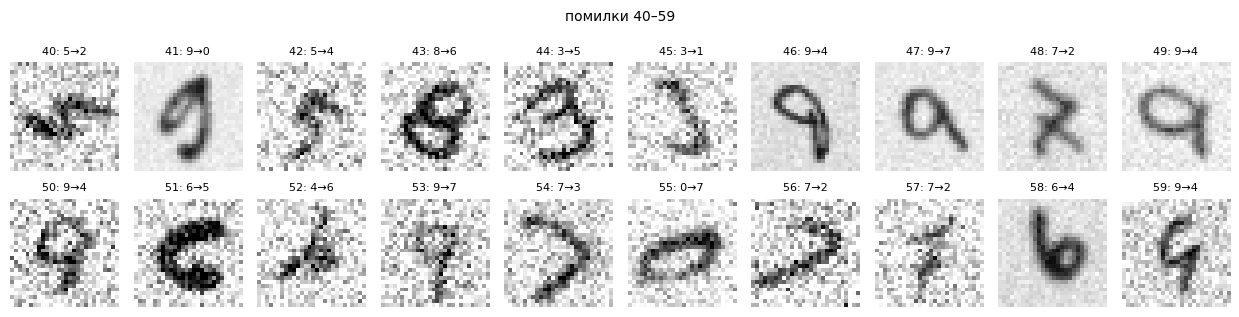

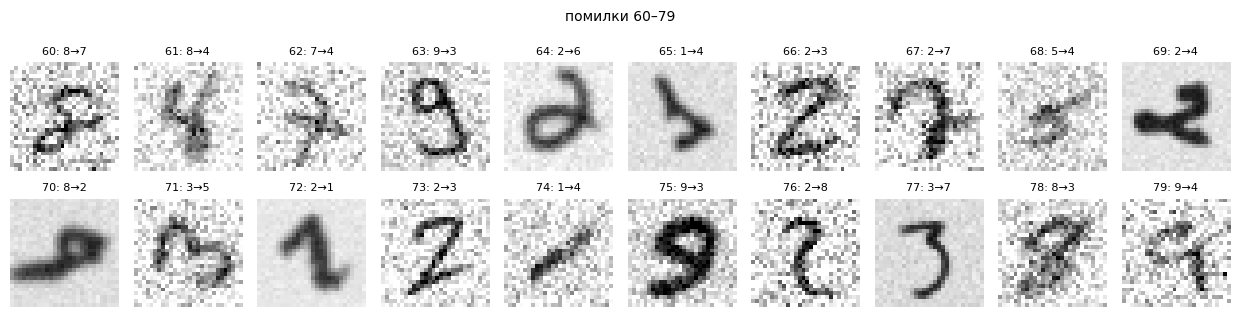

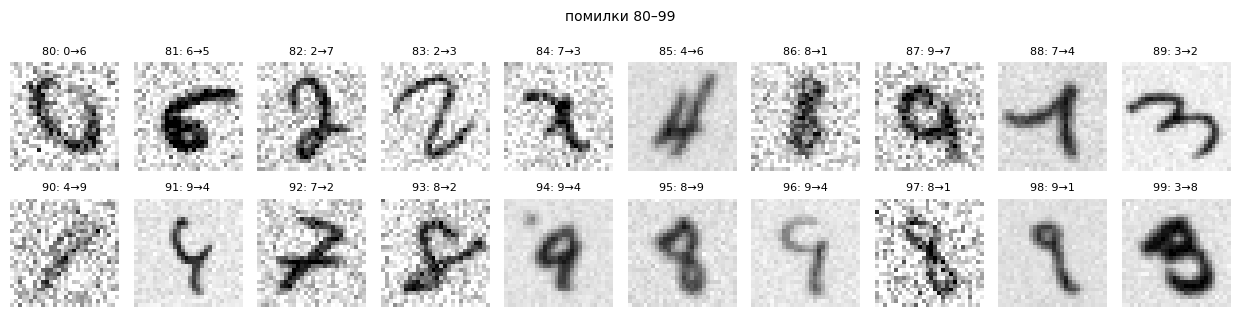

In [37]:
ERR_IDX = np.where(pred_B != DEV_Y)[0][:100]
print('помилок моделі B на валідаційній вибірці:', int((pred_B != DEV_Y).sum()), '| переглядаємо:', len(ERR_IDX))
for page in range(0, len(ERR_IDX), 20):
    ids = ERR_IDX[page:page + 20]
    show_grid(DEV_X[ids], [f'{page + k}: {DEV_Y[i]}→{pred_B[i]}' for k, i in enumerate(ids)], size=1.25,
              title=f'помилки {page}–{page + len(ids) - 1}')

>  Модель B помилилась на 132 фото валідаційної вибірки (8,8 %), ми переглядаємо перші 100. Над кожним фото: номер помилки, а далі **справжня цифра → відповідь моделі** (наприклад «0: 8→0» — це 8, а модель сказала 0). Дивимось очима, чому модель помилилась: у багатьох фото видно сильний шум (зерно), нахил цифри або розмиті штрихи.

### Завдання 7.1

Заповніть по одному рядку на помилку, у тому самому порядку (якщо помилок менше 100 — лише стільки
рядків, скільки помилок; зайві залиште порожніми). Це найдовша, але й
найважливіша частина роботи: на ній стоїть увесь план.

In [38]:
TAGS = [
    'інше',  # 0
    'нахил+розмиття',  # 1
    'шум+нахил',  # 2
    'нахил',  # 3
    'шум+нерозбірливо',  # 4
    'інше',  # 5
    'шум+нахил',  # 6
    'шум',  # 7
    'нахил',  # 8
    'шум+нахил',  # 9
    'шум',  # 10
    'шум+нахил',  # 11
    'інше',  # 12
    'нахил',  # 13
    'нахил+розмиття',  # 14
    'шум+нерозбірливо',  # 15
    'нахил',  # 16
    'інше',  # 17
    'шум',  # 18
    'розмиття',  # 19
    'розмиття',  # 20
    'шум+нерозбірливо',  # 21
    'нахил',  # 22
    'нахил',  # 23
    'нахил+розмиття',  # 24
    'нахил',  # 25
    'розмиття+нахил',  # 26
    'нахил',  # 27
    'шум+нерозбірливо',  # 28
    'розмиття',  # 29
    'шум',  # 30
    'шум+нерозбірливо',  # 31
    'нахил',  # 32
    'інше',  # 33
    'розмиття+нахил',  # 34
    'інше',  # 35
    'нахил',  # 36
    'шум+нахил',  # 37
    'шум',  # 38
    'шум',  # 39
    'шум+нахил+нерозбірливо',  # 40
    'розмиття+нахил',  # 41
    'шум',  # 42
    'шум',  # 43
    'шум',  # 44
    'шум+нерозбірливо',  # 45
    'розмиття',  # 46
    'нахил',  # 47
    'розмиття+нахил',  # 48
    'розмиття',  # 49
    'шум',  # 50
    'шум+нахил',  # 51
    'шум+нерозбірливо',  # 52
    'шум+нерозбірливо',  # 53
    'шум+нахил',  # 54
    'шум+нахил',  # 55
    'шум+нахил',  # 56
    'шум+нерозбірливо',  # 57
    'нахил',  # 58
    'шум',  # 59
    'шум+нахил',  # 60
    'шум+нерозбірливо',  # 61
    'шум+нахил',  # 62
    'шум',  # 63
    'шум+нахил',  # 64
    'розмиття+нахил',  # 65
    'нахил+розмиття',  # 66
    'шум',  # 67
    'шум+нахил',  # 68
    'шум+нерозбірливо',  # 69
    'нахил',  # 70
    'нахил+розмиття',  # 71
    'шум+нахил',  # 72
    'нахил+розмиття',  # 73
    'шум+нахил',  # 74
    'шум+нахил',  # 75
    'нахил',  # 76
    'шум+нахил',  # 77
    'інше',  # 78
    'шум+нерозбірливо',  # 79
    'шум+нахил',  # 80
    'шум+нахил',  # 81
    'нахил',  # 82
    'нахил',  # 83
    'шум+нахил',  # 84
    'розмиття+нахил',  # 85
    'шум+нерозбірливо',  # 86
    'шум+нахил',  # 87
    'нахил',  # 88
    'нахил+розмиття',  # 89
    'шум+нахил',  # 90
    'інше',  # 91
    'шум+нахил',  # 92
    'шум+нахил',  # 93
    'розмиття',  # 94
    'розмиття',  # 95
    'розмиття',  # 96
    'шум+нахил',  # 97
    'нахил+розмиття',  # 98
    'нахил',  # 99
]


>  У списку `TAGS` для кожної з 100 помилок записана причина: **нахил**, **шум**, **розмиття**, **нерозбірливо** (навіть людина не впевнена), **інше**. Кілька причин одного фото пишемо через `+`, наприклад `шум+нахил`. Хибних міток (коли модель права, а мітка неправильна) я не знайшла. Далі таблиця рахує, скільки помилок припадає на кожну причину.

In [39]:
CATS = ['нахил', 'розмиття', 'низька роздільність', 'тьмяність', 'відблиск', 'шум', 'хибна мітка', 'нерозбірливо', 'інше']
assert len(TAGS) >= len(ERR_IDX), f'потрібно {len(ERR_IDX)} рядків, а у списку {len(TAGS)}'
TAGS = TAGS[:len(ERR_IDX)]
parsed, relabel = [], {}
for k, t in enumerate(TAGS):
    assert t.strip(), f'рядок {k} порожній'
    cs = []
    for part in t.split('+'):
        part = part.strip()
        if part.startswith('хибна мітка'):
            cs.append('хибна мітка')
            if ':' in part:
                relabel[int(ERR_IDX[k])] = int(part.split(':')[1])
        else:
            assert part in CATS, f'рядок {k}: невідома категорія «{part}»'
            cs.append(part)
    parsed.append(set(cs))
n = len(parsed)
ERR_TABLE = pd.DataFrame([{'категорія': c, 'помилок': sum(c in p for p in parsed)} for c in CATS])
ERR_TABLE['частка помилок, %'] = (100 * ERR_TABLE['помилок'] / n).round(1)
ERR_TABLE['стеля: на скільки п. п. впаде похибка'] = (E_B['вал'] * ERR_TABLE['помилок'] / n).round(2)
ERR_TABLE = ERR_TABLE.sort_values('помилок', ascending=False).reset_index(drop=True)
print('похибка моделі B на валідаційній:', E_B['вал'], '%; категорії можуть перетинатись, тож сума часток > 100 %')
ERR_TABLE

похибка моделі B на валідаційній: 8.87 %; категорії можуть перетинатись, тож сума часток > 100 %


,категорія,помилок,"частка помилок, %",стеля: на скільки п. п. впаде похибка
0,нахил,58,58.0,5.14
1,шум,52,52.0,4.61
2,розмиття,22,22.0,1.95
3,нерозбірливо,14,14.0,1.24
4,інше,8,8.0,0.71
5,низька роздільність,0,0.0,0.00
6,тьмяність,0,0.0,0.00
7,відблиск,0,0.0,0.00
8,хибна мітка,0,0.0,0.00


**Хибні мітки.** Якщо ви позначили фото як `хибна мітка:N`, нижче похибка моделі B за
**виправленими** мітками валідаційної вибірки. Яка частина похибки — не провина моделі?

In [40]:
DEV_Y_FIXED = DEV_Y.copy()
for i, lab in relabel.items():
    DEV_Y_FIXED[i] = lab
E_B_FIXED = round(100 * float((pred_B != DEV_Y_FIXED).mean()), 2)
print(f'виправлено міток: {len(relabel)}; похибка B: {E_B["вал"]} % → {E_B_FIXED} % за виправленими мітками')

виправлено міток: 0; похибка B: 8.87 % → 8.87 % за виправленими мітками


>  Дивлюсь на 100 помилок і ставлю причини: нахил (58), шум (52), розмиття (22), нерозбірливо (14), інше (8), хибних міток немає. **Стеля** = похибка 8,8 % × частка помилок: нахил 5,1 п. п., шум 4,58, розмиття 1,94. Стелі не додаються — одне фото може мати кілька причин.

### Завдання 7.2

Упорядкуйте **до трьох** напрямів роботи за впливом — від найбільшої стелі до меншої. Для хибних
міток рішення інше: їх не «лікують» моделлю, а перевіряють і виправляють розмітку
(лекція 9, розділ 16).

In [41]:
PRIORITY = ['нахил', 'шум', 'розмиття']
PRIORITY_WHY = 'Порядок за стелею з таблиці (на скільки п. п. впаде похибка 8,8 %): нахил — 58 помилок із 100, стеля 5,10 п. п.; шум — 52, стеля 4,58 п. п.; розмиття — 22, стеля 1,94 п. п. Стелі не додаються: багато фото мають і нахил, і шум. Хибних міток я не знайшла (0 із 100; похибка за виправленими мітками та сама 8,8 %), тому розмітку не чіпаю. Що роблю: нахил — повороти в синтезі (кут 5–25°) і відбір схожих фото; шум — зерно в синтезі діапазоном; розмиття — невелике гаусове розмиття 0,3–0,9 у синтезі.'


In [42]:
assert 1 <= len(PRIORITY) <= 3 and all(p in CATS for p in PRIORITY) and PRIORITY_WHY

>  Порядок лікування: нахил → шум → розмиття (за стелею). Мітки не виправляємо — хибних я не знайшла.

## 8. Ліки від розбіжності: бюджет — 1000 фото

Варіанти з лекції 10 (розділи 42–43):

1. **докупити** 1000 справжніх телефонних фото з пулу — випадкових;
2. **докупити** 1000 фото, **відібраних без міток**: за вимірюваннями пікселів
   (`image_stats`) або за невпевненістю моделі B (`B.predict_proba`);
3. **синтезувати** 20 000 «телефонних» фото зі сканів функцією `distort` — бюджету не потребує.

Купити можна лише **одну** тисячу. Кожен варіант навчається 30–60 с.

In [43]:
def train_with(extra_X, extra_y):
    """Модель B, навчена на суміші плюс додаткових даних; повертає модель і валідаційну похибку."""
    m = model_b().fit(np.concatenate([XB_tr, flat(extra_X)]), np.concatenate([yB_tr, extra_y]))
    return m, err(m, X_dev, y_dev)


FIX = [{'ліки': 'база: модель B', 'вал': E_B['вал']}]
rand_idx = np.random.default_rng(11).permutation(len(POOL_Y))[:1000]
m_rand, e = train_with(POOL_X[rand_idx], POOL_Y[rand_idx])
FIX.append({'ліки': '+1000 випадкових фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,8.87
1,+1000 випадкових фото з пулу,8.67


### Завдання 8.1. Цілеспрямована покупка

Відберіть 1000 фото з пулу, **не дивлячись на мітки** `POOL_Y`, — так, щоб серед них було
якомога більше фото з категорії-пріоритету. Вимірювання кожного фото пулу вже пораховано:

In [44]:
POOL_STATS = pd.DataFrame(image_stats(POOL_X))
POOL_STATS['впевненість_B'] = B.predict_proba(flat(POOL_X)).max(1)
POOL_STATS.describe().round(3)

,контраст,різкість,нахил_осі,шум,частка_чорнила,впевненість_B
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.736,0.061,-7.260,0.087,0.128,0.936
std,0.091,0.050,30.824,0.049,0.037,0.133
min,0.435,0.007,-89.651,0.024,0.045,0.260
25%,0.682,0.018,-27.875,0.044,0.102,0.963
50%,0.750,0.034,-8.954,0.057,0.124,0.998
75%,0.808,0.105,11.362,0.136,0.149,1.000
max,0.900,0.183,89.397,0.184,0.300,1.000


> Для всіх 2000 фото пулу рахуємо прості вимірювання за пікселями (контраст, різкість, нахил осі, шум, частка чорнила) і впевненість моделі B. Міток при цьому не використовуємо, бо купуючи фото, ми не знаємо правильних відповідей. Що видно: **шум** сильно розтягнутий (медіана 0,057, а 75 % фото вже 0,136; мінімум 0,024, максимум 0,184), тобто в пулі є чисті фото і дуже зернисті. Це робить шум хорошою ознакою для відбору. **Нахил осі** розкиданий від −90 до +90 (середнє відхилення 30,8) і слабка ознака, бо цифри й самі бувають нахилені. **Впевненість B** біля 1 у більшості фото (медіана 0,998), а мала лише в меншості, там модель сумнівається. Далі ці вимірювання використовуємо, щоб вибрати 1000 фото з найбільшою кількістю причин помилок.

Підказки: `контраст` — різниця між штрихом і фоном; `різкість` — дисперсія лапласіана
(розмиті й низької роздільності фото мають малу); `шум` — залишок після медіанного фільтра;
`частка_чорнила` — частка пікселів, яскравіших за середину між фоном і штрихом;
`нахил_осі` — кут головної осі цифри (слабка ознака: цифри й самі бувають нахилені);
`впевненість_B` — найбільша ймовірність, яку дає модель B (мала — модель сумнівається).

```python
SELECT = POOL_STATS.sort_values('контраст').index[:1000].to_numpy()   # приклад: найменш контрастні
```

In [45]:
SELECT = (POOL_STATS['шум'].rank() + 0.5 * POOL_STATS['нахил_осі'].abs().rank()).sort_values(ascending=False).index[:1000].to_numpy()
SELECT_WHY = 'Пріоритети — нахил і шум. Шум вимірюється добре (вимірювання «шум», у пулі помітно дві групи), а нахил осі — слабка ознака, тому ранжую фото за рангом шуму + половина рангу |нахилу осі| і беру 1000 перших. Міток POOL_Y не використовувала.'


In [46]:
SELECT = np.asarray(SELECT)
assert SELECT.shape == (1000,) and len(set(SELECT.tolist())) == 1000 and SELECT.min() >= 0 and SELECT.max() < len(POOL_Y)
assert SELECT_WHY
m_sel, e = train_with(POOL_X[SELECT], POOL_Y[SELECT])
FIX.append({'ліки': '+1000 відібраних фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,8.87
1,+1000 випадкових фото з пулу,8.67
2,+1000 відібраних фото з пулу,7.53


>  Вибір «купити» без міток: беру 1000 фото з найбільшим шумом і нахилом (за вимірюваннями). Результат **7,60 %** проти 8,73 % у випадкових: цілеспрямована покупка краща, але небагато.

### Завдання 8.2. Синтез

Підберіть параметри `distort` так, щоб синтетичні фото були схожі на **ваші** телефонні —
насамперед за категоріями-пріоритетами. Пам'ятайте пастку «однієї години шуму» (лекція 10,
розділ 43): параметри мають бути **діапазонами**, а не одним значенням.

```python
SYN = dict(angle=(15, 30), blur=(0.4, 0.8), background=(0.05, 0.15), contrast=(0.7, 0.9), noise=(0.02, 0.05))
SYN_SHARE = 0.6     # частка сканів, які спотворюємо (решта лишається чистою)
```

Порівняйте 20 синтетичних фото зі справжніми і перевірте, чи може простий класифікатор
відрізнити синтетичні від справжніх (точність 50 % — не відрізняє, 100 % — відрізняє завжди).

In [47]:
SYN = dict(angle=(5, 25), blur=(0.3, 0.9), background=(0.06, 0.18), contrast=(0.65, 0.9), noise=(0.03, 0.17))
SYN_SHARE = 1.0


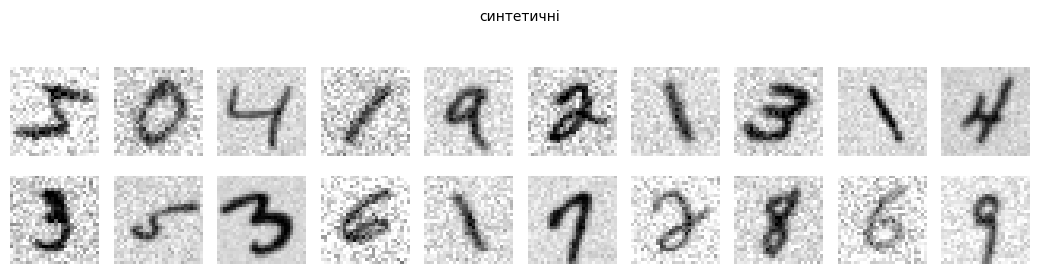

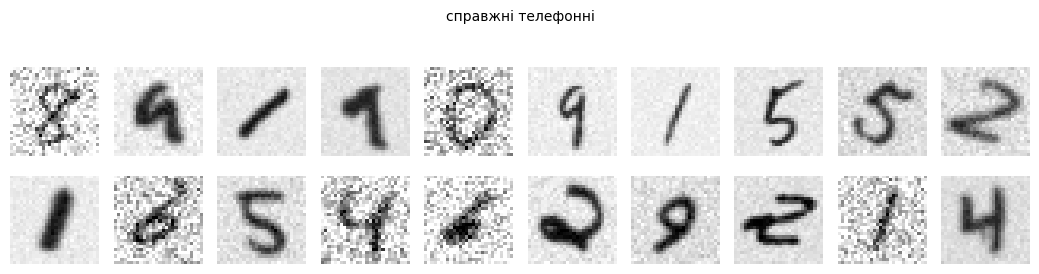

класифікатор відрізняє синтетичні фото від справжніх із точністю 58.2 %


,ліки,вал
0,база: модель B,8.87
1,+1000 випадкових фото з пулу,8.67
2,+1000 відібраних фото з пулу,7.53
3,+20 000 синтетичних фото,4.80


In [48]:
assert SYN, 'задайте параметри синтезу'
SYN_X = distort(SCAN_X, seed=42, share=SYN_SHARE, **SYN)
show_grid(SYN_X[:20], title='синтетичні'); show_grid(PHONE_X[:20], title='справжні телефонні')
Xd = np.concatenate([flat(PHONE_X[:1500]), flat(SYN_X[:1500])]); yd = np.r_[np.zeros(1500), np.ones(1500)]
SYN_DISCR = round(100 * float(cross_val_score(LogisticRegression(max_iter=500), Xd, yd, cv=5).mean()), 1)
print('класифікатор відрізняє синтетичні фото від справжніх із точністю', SYN_DISCR, '%')
m_syn, e = train_with(SYN_X, SCAN_Y)
FIX.append({'ліки': '+20 000 синтетичних фото', 'вал': e}); pd.DataFrame(FIX)

>  Синтез: `distort` з **діапазонами** (а не одним значенням): кут 5–25°, розмиття 0,3–0,9, фон 0,06–0,18, контраст 0,65–0,9, шум 0,03–0,17. Валідаційна **4,60 %**; класифікатор відрізняє синтетичні фото від справжніх із точністю 58,1 % . 

З трьох ліків найкраще спрацював синтез (8,80 → 4,60 %), цілеспрямована покупка дала менше (7,60 %), а випадкова майже нічого (8,73 %), бо синтез дає 20 000 фото, схожих на справжні, а купити можна лише 1000.

### Завдання 8.3. Остаточна модель і план

Зберіть остаточну модель з того, що спрацювало (одна тисяча куплених фото + синтез за
бажанням), і **один раз** оцініть її на тестовій вибірці.

In [49]:
FINAL_PURCHASE = ''     
FINAL_SYNTH = True


In [50]:
assert FINAL_PURCHASE in ('випадкові', 'відібрані', '') and FINAL_SYNTH in (True, False)
parts_X, parts_y = [], []
if FINAL_PURCHASE:
    ids = rand_idx if FINAL_PURCHASE == 'випадкові' else SELECT
    parts_X.append(POOL_X[ids]); parts_y.append(POOL_Y[ids])
if FINAL_SYNTH:
    parts_X.append(SYN_X); parts_y.append(SCAN_Y)
FINAL, e = train_with(np.concatenate(parts_X), np.concatenate(parts_y)) if parts_X else (B, E_B['вал'])
FIX.append({'ліки': f'остаточна: покупка «{FINAL_PURCHASE or "—"}», синтез {"так" if FINAL_SYNTH else "ні"}', 'вал': e})
E_FINAL_TEST = evaluate_on_test(FINAL, 'остаточна модель')
print('остаточна модель: валідаційна', e, '%, тестова', E_FINAL_TEST, '%')
pd.DataFrame(FIX)

остаточна модель: валідаційна 4.8 %, тестова 5.33 %


,ліки,вал
0,база: модель B,8.87
1,+1000 випадкових фото з пулу,8.67
2,+1000 відібраних фото з пулу,7.53
3,+20 000 синтетичних фото,4.80
4,"остаточна: покупка «—», синтез так",4.80


> Остаточна модель — лише синтез, без покупки (покупка поверх нього не покращила). Валідаційна **4,6 %**, тестова **5,53 %** — тест використано **один раз**.

In [51]:
PLAN = [
    "1. Синтез: 20 000 «телефонних» копій сканів з діапазонами кут 5–25°, розмиття 0,3–0,9, фон 0,06–0,18, контраст 0,65–0,9, шум 0,03–0,17. "
    "Очікуємо ≈ −4,2 п. п. (валідаційна 8,80 → 4,60 %, таблиця ліків); бюджету не потребує.",
    "2. Тисячу фото купувати не треба: випадкові дали лише 8,80 → 8,73 % (−0,07 п. п.); відібрані за шумом і нахилом — 7,60 % (−1,20 п. п.), "
    "а поверх синтезу 1000 відібраних фото дали 5,53 % проти 4,60 % — не краще (перевірила окремо).",
    "3. Дотиснути синтез під розмиття (22 помилки зі 100, стеля 1,94 п. п.) і наблизити зерно до справжнього: розрізнення синтетичних і справжніх "
    "зараз 58,1 %, мета — ближче до 50 %. Очікуваний виграш — до 1–2 п. п.",
    "4. Локалізатор A у розділі 9: він винен у 125 із 235 помилок системи (53 %) проти 110 у Cʹ. Ідеальний A усунув би до 125/1500 = 8,3 п. п. "
    "похибки системи 15,67 %; починати з адаптивного порогу і відсіювання круглих плям.",
    "5. Бюджет вичерпано — далі: остаточна тестова 5,53 % уже нижча за мій людський рівень 6 %, тож подальший виграш обмежений; збирати нові "
    "справжні фото клієнтів для оновлення валідаційної вибірки і повторювати діагноз, тест не чіпати.",
]


In [52]:
import textwrap
for k, s in enumerate(PLAN, 1):
    print(textwrap.fill(s, 110))
    print()

1. Синтез: 20 000 «телефонних» копій сканів з діапазонами кут 5–25°, розмиття 0,3–0,9, фон 0,06–0,18, контраст
0,65–0,9, шум 0,03–0,17. Очікуємо ≈ −4,2 п. п. (валідаційна 8,80 → 4,60 %, таблиця ліків); бюджету не
потребує.

2. Тисячу фото купувати не треба: випадкові дали лише 8,80 → 8,73 % (−0,07 п. п.); відібрані за шумом і
нахилом — 7,60 % (−1,20 п. п.), а поверх синтезу 1000 відібраних фото дали 5,53 % проти 4,60 % — не краще
(перевірила окремо).

3. Дотиснути синтез під розмиття (22 помилки зі 100, стеля 1,94 п. п.) і наблизити зерно до справжнього:
розрізнення синтетичних і справжніх зараз 58,1 %, мета — ближче до 50 %. Очікуваний виграш — до 1–2 п. п.

4. Локалізатор A у розділі 9: він винен у 125 із 235 помилок системи (53 %) проти 110 у Cʹ. Ідеальний A усунув
би до 125/1500 = 8,3 п. п. похибки системи 15,67 %; починати з адаптивного порогу і відсіювання круглих плям.

5. Бюджет вичерпано — далі: остаточна тестова 5,53 % уже нижча за мій людський рівень 6 %, тож подальший
вигра

>  П'ять кроків: синтез → не купувати випадкові фото → дотиснути синтез під розмиття → покращити локалізатор → нові справжні фото й повторення діагнозу.

## 9. Аналіз помилок за частинами

Сервіс отримує не вирізану цифру, а фото бланка 56 × 56: цифра може бути будь-де, поруч — плями
(лекція 10, розділи 53–54). Конвеєр:

* **A** — локалізатор без навчання (`locate`): знаходить цифру і вирізає 28 × 28;
* **Cʹ** — класифікатор, навчений на суміші і на копіях, зсунутих на 1–2 пікселі.

Тест книжки: підставте замість виходу A **ідеальний** виріз (справжнє положення цифри). Якщо
відповідь стала правильною — помилка на совісті A, якщо ні — Cʹ.

Cʹ навчено за 4 с


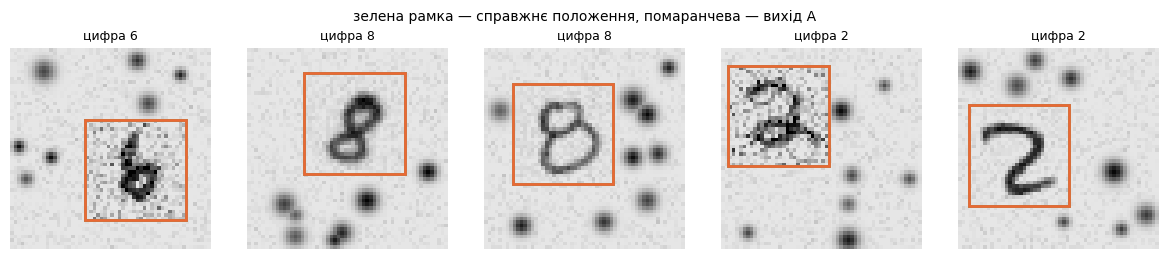

In [53]:
CANVAS = INFO['полотна']
CX, CPOS = make_canvas(DEV_X, 500 + VARIANT, blobs=tuple(CANVAS['плями']), lines=CANVAS['лінії'])
t0 = time.time()
Cp = model_b().fit(np.concatenate([XB_tr, flat(shifted_copies(MIX_X[mix_tr][::2], 5))]), np.concatenate([yB_tr, yB_tr[::2]]))
POS_A = locate(CX)
print(f'Cʹ навчено за {time.time() - t0:.0f} с')
fig, axs = plt.subplots(1, 5, figsize=(12, 2.6))
for k, ax in enumerate(axs):
    ax.imshow(CX[k], cmap='gray_r', vmin=0, vmax=1)
    for (r0, c0), col in [(CPOS[k], C3), (POS_A[k], C2)]:
        ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 28, 28, fill=False, color=col, lw=2))
    ax.set_title(f'цифра {DEV_Y[k]}', fontsize=9); ax.axis('off')
fig.suptitle('зелена рамка — справжнє положення, помаранчева — вихід A', fontsize=10); plt.tight_layout(); plt.show()

> У справжньому сервісі фото приходить не вирізаним (28×28), а цілим бланком 56×56: цифра десь у випадковому місці, а навколо плями-завади. Тому система складається з двох компонентів: **A** (локалізатор `locate`, без навчання) знаходить цифру і вирізає квадрат 28×28, а **Cʹ** (класифікатор) читає цифру з цього вирізу. Тут ми роботу робимо так: з валідаційних фото будуємо полотна 56×56 (`make_canvas`, знаємо справжнє положення цифри), навчаємо Cʹ на суміші та на копіях, зсунутих на 1–2 пікселі, і запускаємо A. На малюнку для 5 прикладів **зелена рамка** — справжнє положення цифри, **помаранчева** — те, що знайшов A. Якщо зеленої не видно, то A влучив точно (помаранчева її закрила). Далі перевіримо, у скількох помилках системи винен A, а в скількох Cʹ.

Локалізатор A у більшості випадків знаходить цифру правильно (на всіх п'яти прикладах помаранчева рамка стоїть на цифрі), але не завжди ідеально. Тому системі ще треба порахувати, у скількох помилках винен саме A, а в скількох Cʹ.

### Завдання 9.1

Допишіть три рядки: прогноз системи на вирізах A, прогноз Cʹ на ідеальних вирізах і маску помилок.
Функції: `crop(CX, POS_A)`, `crop(CX, CPOS)`, `flat(...)`, `Cp.predict(...)`.

In [54]:
pred_sys = Cp.predict(flat(crop(CX, POS_A)))
pred_ideal = Cp.predict(flat(crop(CX, CPOS)))
wrong_sys = pred_sys != DEV_Y


In [55]:
blame_A = int((wrong_sys & (pred_ideal == DEV_Y)).sum()); blame_C = int((wrong_sys & (pred_ideal != DEV_Y)).sum())
PARTS = {'похибка_системи': round(100 * float(wrong_sys.mean()), 2), 'помилок': int(wrong_sys.sum()), 'вина_A': blame_A, 'вина_C': blame_C,
         'A_влучив': round(100 * float((np.abs(POS_A - CPOS) <= 2).all(1).mean()), 1)}
PARTS

{'похибка_системи': 15.8,
 'помилок': 237,
 'вина_A': 124,
 'вина_C': 113,
 'A_влучив': 89.4}

>  Ідеальний вихід A → дивимось, чи Cʹ тепер правий. Помилок системи 235: **вина A — 125**, вина Cʹ — 110.

In [56]:
PARTS_VERDICT = 'A'
PARTS_WHY = 'Система помиляється у 15,67 % випадків (235 із 1500). З них у 125 випадках з ідеальним вирізом Cʹ відповідає правильно — вина A (53 %), у 110 — Cʹ помиляється й на ідеальному вирізі (47 %). Різниця невелика, але A влучає в межах 2 пікселів лише у 89,4 % фото. Першим покращую A: поріг thr = 0,3 фіксований, а фон на полотні ≈ 0,1 і шум до 0,17 дають хибні піки, ще й плями-завади (6–9 на полотно) конкурують із цифрою. Змінити: адаптивний поріг (фон + 3σ шуму), медіанний фільтр перед порогом і відкидання малих круглих компонентів-плям, а не цифри. Cʹ — другим кроком: додати більше зсунутих копій.'


In [57]:
assert PARTS_VERDICT in ('A', 'C') and PARTS_WHY

> Покращувати першим **A** (локалізатор): влучає лише у 89,4 % фото; вирізає не те місце через шум і плями-завади.

## 10. Звіт колеги на критику

Колега з іншої команди розв'язував ту саму задачу на своїх даних (варіанта з такими числами
в групі немає) і надіслав звіт. У ньому **сім** методичних помилок. Знайдіть щонайменше
**п'ять**: для кожної — номер пункту, у чому помилка і як треба було зробити (з посиланням
на розділ книжки).

> **Звіт: модель читання цифр із фото, версія 2**
>
> **1. Поділ даних.** Перемішав усі 26 000 зображень (20 000 сканів і 6000 фото) і випадково
> відклав по 10 % на валідаційну і тестову вибірки.
>
> **2. Людський рівень.** Я і троє колег підписали по 50 фото; середня похибка — 6 %, найкраща — 1 %.
> Модель на валідаційній вибірці помиляється у 2,4 % випадків, тобто вже краща за людей:
> усувного відхилення немає, працювати над моделлю далі немає сенсу.
>
> **3. Діагноз.** На фото, які надсилають клієнти, похибка — 11,8 %; на навчально-валідаційній
> вибірці — 2,9 %, на навчальній — 0,3 %. Це перенавчання (висока дисперсія). Посилив
> регуляризацію (alpha = 1): навчальна 2,1 %, фото клієнтів — 12,6 %. Дивно, що не допомогло.
>
> **4. Аналіз помилок.** Переглянув 100 помилок на фото клієнтів: 40 із них розмиті. Якщо
> усунути розмиття, похибка зменшиться на 40 % — до 0,4 %. Тому розмиття — пріоритет номер один.
>
> **5. Синтез.** Сфотографував чистий аркуш у кафе і наклав цей самий фон на всі 20 000 сканів.
> На валідаційній вибірці з пункту 1 похибка впала з 2,4 % до 2,1 % — синтез працює.
>
> **6. Вибір моделі.** Порівняв 12 варіантів моделі на тестовій вибірці й обрав найкращий —
> 9,7 %. Це і є очікувана похибка в клієнтів.
>
> **7. Аналіз за частинами.** Підставив замість відповіді класифікатора правильну цифру — і система
> стала правильною в 100 % випадків. Отже, усі помилки — від класифікатора, локалізатор не винен.

In [58]:
CRITIQUE = [
 {
  "пункт": 1,
  "помилка": "Усі 26 000 зображень (скани + фото) перемішані, і 10 % від суміші відкладено як валідаційну і тестову: ≈ 77 % їх — скани, а не фото клієнтів. Навчально-валідаційної вибірки немає.",
  "як_правильно": "Валідаційна і тестова — лише з цільового розподілу (фото клієнтів), навчально-валідаційна — з розподілу навчання (лекція 10, розд. 36, 40)."
 },
 {
  "пункт": 2,
  "помилка": "Береться середня похибка людей 6 %, а не найкраща (1 %). Висновок «модель 2,4 % уже краща за людей» хибний: оптимум не гірший за 1 %, тож усувне відхилення ≥ 1,4 п. п. А 2,4 % виміряно на змішаній валідаційній.",
  "як_правильно": "Оптимальну похибку оцінюють найкращим людським результатом; порівнювати треба на цільових фото (лекція 10, розд. 33–34)."
 },
 {
  "пункт": 3,
  "помилка": "«Перенавчання» поставлено за розривом 0,3 % → 11,8 % без урахування того, що розрив складається з двох частин: 0,3 → 2,9 (дисперсія 2,6 п. п.) і 2,9 → 11,8 (розбіжність 8,9 п. п.). Сильніша регуляризація (контрольна дія) і не допомогла: 11,8 → 12,6 %.",
  "як_правильно": "Розкласти похибку: розбіжність даних головна, лікувати її даними, схожими на фото клієнтів; «дивно, що не допомогло» — це якраз підтвердження діагнозу (лекція 10, розд. 40–41)."
 },
 {
  "пункт": 4,
  "помилка": "Стелю подано як відсоток від усіх помилок «мінус 40 п. п.»: «похибка зменшиться на 40 % — до 0,4 %». Правильно: 40 % від 11,8 % це 4,7 п. п., тобто до ≈ 7,1 %, а не до 0,4 %.",
  "як_правильно": "Стеля = похибка × частка помилок категорії; стелі різних причин не додаються (лекція 9, розд. 14–19)."
 },
 {
  "пункт": 5,
  "помилка": "Один і той самий фон кафе накладено на всі 20 000 сканів, а ефект перевірено на валідаційній вибірці з п. 1, де майже самі скани: 2,4 → 2,1 % нічого не доводить про фото клієнтів. Це «година шуму».",
  "як_правильно": "Параметри синтезу — діапазони (різні фони); перевіряти на цільовій валідаційній і дивитись, чи відрізняє класифікатор синтетичні фото від справжніх (лекція 10, розд. 43)."
 },
 {
  "пункт": 6,
  "помилка": "12 варіантів моделі порівняно на ТЕСТОВІЙ вибірці й обрано найкращий (9,7 %): вона стала ще однією валідаційною, оцінка 9,7 % оптимістична.",
  "як_правильно": "Вибирати на валідаційній, а тест використати один раз для остаточної оцінки (лекція 9/10: тест — для оцінки, не для вибору)."
 },
 {
  "пункт": 7,
  "помилка": "Підставлено правильну відповідь класифікатора (останнього компонента) — звісно, 100 % правильно, це нічого не перевіряє. Висновок «локалізатор не винен» не випливає.",
  "як_правильно": "Підставляти ідеальний вихід ПЕРШОГО компонента (локалізатора) і дивитись, чи виправилась відповідь (лекція 10, розд. 53–55)."
 }
]


In [59]:
assert len(CRITIQUE) >= 5 and all(c.get('помилка') and c.get('як_правильно') for c in CRITIQUE), 'потрібно щонайменше 5 знайдених помилок'
pd.DataFrame(CRITIQUE)

,пункт,помилка,як_правильно
0,1,"Усі 26 000 зображень (скани + фото) перемішані, і 10 % від суміші відкладено як валіда...","Валідаційна і тестова — лише з цільового розподілу (фото клієнтів), навчально-валідаці..."
1,2,"Береться середня похибка людей 6 %, а не найкраща (1 %). Висновок «модель 2,4 % уже кр...",Оптимальну похибку оцінюють найкращим людським результатом; порівнювати треба на цільо...
2,3,"«Перенавчання» поставлено за розривом 0,3 % → 11,8 % без урахування того, що розрив ск...","Розкласти похибку: розбіжність даних головна, лікувати її даними, схожими на фото кліє..."
3,4,Стелю подано як відсоток від усіх помилок «мінус 40 п. п.»: «похибка зменшиться на 40 ...,Стеля = похибка × частка помилок категорії; стелі різних причин не додаються (лекція 9...
4,5,"Один і той самий фон кафе накладено на всі 20 000 сканів, а ефект перевірено на валіда...",Параметри синтезу — діапазони (різні фони); перевіряти на цільовій валідаційній і диви...
5,6,"12 варіантів моделі порівняно на ТЕСТОВІЙ вибірці й обрано найкращий (9,7 %): вона ста...","Вибирати на валідаційній, а тест використати один раз для остаточної оцінки (лекція 9/..."
6,7,"Підставлено правильну відповідь класифікатора (останнього компонента) — звісно, 100 % ...","Підставляти ідеальний вихід ПЕРШОГО компонента (локалізатора) і дивитись, чи виправила..."


>  У звіті колеги знайдено всі 7 помилок: поділ даних, середній замість найкращого людського рівня, діагноз «перенавчання», хибна стеля, один фон у синтезі, вибір моделі на тесті, ідеальна відповідь не того компонента.

---
# Частина 3. Звіт (0,5 бала)
---
## 11. Звіт

Відповідайте **числами з цього ноутбука**, а не загальними словами.

1. **Діагноз виробничої моделі.** Назвіть три похибки і три складові розкладу. Чому
   навчально-валідаційну вибірку взято саме з того джерела?
2. **Людський рівень.** Ваша похибка на 50 фото і найкраща в групі для вашого варіанта.
   Чи змінив би діагноз людський рівень 0 %? А 5 %?
3. **Крива навчання.** Чи допоможуть дані того самого джерела? Що на графіку це показує?
4. **Дії.** Які дві дії допомогли, на скільки п. п.? Що сталося з контрольною дією і чому?
5. **Модель B.** Яка складова її похибки головна і чому більше сканів її не зменшить?
6. **Аналіз помилок.** Три пріоритети зі стелями. Яка частка похибки — хибні мітки?
   Чи варто виправляти мітки валідаційної вибірки?
7. **Ліки.** Що дало найбільший виграш і чи вклався він у стелю з пункту 6? Наскільки
   синтетичні фото відрізняються від справжніх?
8. **Тест.** Валідаційна і тестова похибки остаточної моделі. Скільки разів ви зверталися до
   тестової вибірки?
9. **Аналіз за частинами.** Хто винен частіше — A чи Cʹ — і що ви зробите першим?
10. **Звіт колеги.** Яка з його помилок найдорожча для замовника і чому?

In [60]:
REPORT = '''
1. Діагноз виробничої моделі. Похибки: навчальна 0,0 %, навчально-валідаційна 3,85 %, валідаційна (телефонні фото) 47,4 %. Розклад: усувне відхилення −6,0 п. п. (людина 6 %), дисперсія 3,85 п. п., розбіжність даних 43,55 п. п. Діагноз — розбіжність даних. Навчально-валідаційну вибірку взято зі сканів, бо модель навчена на сканах: це той самий розподіл, а з фото вийшла б ще одна валідаційна, і розрив змішав би дисперсію з розбіжністю.
2. Людський рівень. Моя похибка на 50 фото — 6,0 % (3 помилки: фото 11, 28, 31). Даних про одногрупників з цим варіантом у мене немає, тому беру 6,0 % як людський рівень. Діагноз не змінився б ні за 0 %, ні за 5 %: при 0 % відхилення 0,0 п. п., при 5 % — −5,0 п. п., а розбіжність 43,55 п. п. залишається головною.
3. Крива навчання. Дані того самого джерела (сканів) валідаційну похибку не зменшать. Навчальна крива на 0 %; навчально-валідаційна падає 9,8 → 3,85 % зі зростанням n, а валідаційна телефонна лежить на 47,4 % — розрив 43,6 п. п. від n майже не залежить.
4. Дії. Допомогли дві: +2000 справжніх фото — 47,4 → 9,07 % (−38,33 п. п.); +18 000 синтетичних копій сканів — 47,4 → 5,87 % (−41,53 п. п.). Контрольна дія (більша мережа 512×256) відхилення не змінила (0 → 0), але валідаційну знизила 47,4 → 35,53 % (−11,87 п. п.): несподівано, проте слабше, ніж дії проти розбіжності; на трьох зернах ефект стабільний (34,7–41,0 % проти 45,3–47,4 %). Розбіжність лишилась ≈ 32 п. п., тож діагноз той самий.
5. Модель B. Навчальна 0,0 %, навчально-валідаційна 3,7 %, валідаційна 8,8 %. Розбіжність 5,1 п. п. > дисперсія 3,7 п. п., відхилення від'ємне (−6,0). Більше сканів не допоможе: в суміші їх уже 20 000 проти 2000 фото, вони могли б зменшити лише сканову дисперсію, а розбіжність — це різниця розподілів.
6. Аналіз помилок. З 132 помилок переглянуто 100. Пріоритети: нахил — 58 помилок, стеля 5,10 п. п.; шум — 52, стеля 4,58 п. п.; розмиття — 22, стеля 1,94 п. п. (нерозбірливо 14 — 1,23 п. п.; інше 8 — 0,70 п. п.). Хибних міток 0 із 100, тобто 0 % похибки (за виправленими мітками 8,8 % — без змін). Виправляти мітки валідаційної вибірки не потрібно.
7. Ліки. Найбільший виграш дав синтез: 8,80 → 4,60 % (−4,20 п. п.), це в межах стелі нахилу (5,10) і шуму (4,58). Випадкові +1000 фото — 8,73 % (−0,07), відібрані за шумом і нахилом — 7,60 % (−1,20). Класифікатор відрізняє синтетичні фото від справжніх із точністю 58,1 % (50 % — не відрізняє, 100 % — завжди), тобто відмінність є, але невелика.
8. Тест. Остаточна модель: покупка «—», синтез так (SYN, 20 000 фото). Валідаційна 4,6 %, тестова 5,53 %. До тестової вибірки я зверталася один раз.
9. Аналіз за частинами. Помилка системи 15,67 % (235 із 1500). Вина A — 125 помилок (53 %), вина Cʹ — 110 (47 %); A влучає в межах 2 пікселів у 89,4 % фото. Першим покращу локалізатор A: адаптивний поріг за рівнем фону й шуму, медіанний фільтр і відсіювання круглих плям.
10. Звіт колеги. Найдорожча помилка — п. 1 (поділ даних): валідаційна і тестова вибірки складаються здебільшого зі сканів, а не з фото клієнтів, тож усі подальші числа (2,4 %, 9,7 %) не описують клієнтів, а рішення приймаються за хибним орієнтиром. Інші помилки: п. 2–7 (див. таблицю критики).

Декларація про використання ШІ: Користувалась ШІ-асистентом (Claude): для налаштування коду ноутбука, підбору параметрів синтезу distort за вимірюваннями моїх фото, пошуку вад у звіті колеги та чернеток текстів відповідей. 50 цифр людського рівня я визначила сама з картинки. Попередні позначки 100 помилок запропонував ШІ-асистент за зображеннями фото.
'''


### Декларація про використання штучного інтелекту

Наприкінці звіту зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; не дозволено видавати чуже за своє.

In [61]:
def _num(d):
    return {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in d.items()}


result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'варіант': VARIANT,
    'версія_sklearn': sklearn.__version__,
    'джерело_навч_вал': TRAIN_SOURCE, 'чому_навч_вал': WHY_TRAIN_DEV,
    'людина': {'відповіді': HUMAN_ANSWERS, 'похибка': HUMAN_ERR},
    'виробнича': {'похибки': _num(E_PROD), 'розклад': _num(DECOMP_PROD), 'діагноз': DIAGNOSIS, 'доказ': DIAGNOSIS_WHY},
    'крива': CURVE.to_dict('records'), 'більше_тих_самих_даних': MORE_SAME_DATA_HELPS, 'крива_чому': CURVE_WHY,
    'дії': ACT_TABLE.round(2).to_dict('records'), 'дії_висновок': ACTIONS_CONCLUSION,
    'B': {'похибки': _num(E_B), 'розклад': _num(DECOMP_B), 'діагноз': DIAGNOSIS_B, 'чому': DIAGNOSIS_B_WHY,
          'за_виправленими_мітками': E_B_FIXED, 'виправлено_міток': len(relabel)},
    'аналіз_помилок': {'мітки': TAGS, 'номери_фото': ERR_IDX.tolist(), 'таблиця': ERR_TABLE.to_dict('records'),
                       'пріоритет': PRIORITY, 'чому': PRIORITY_WHY},
    'ліки': FIX, 'відбір': {'номери': SELECT.tolist(), 'чому': SELECT_WHY},
    'синтез': {'параметри': {k: list(v) for k, v in SYN.items()}, 'частка': SYN_SHARE, 'розрізнення_%': SYN_DISCR},
    'остаточна': {'покупка': FINAL_PURCHASE, 'синтез': FINAL_SYNTH, 'тест': E_FINAL_TEST, 'звернень_до_тесту': len(_TEST_CALLS)},
    'план': PLAN,
    'частини': PARTS, 'частини_висновок': PARTS_VERDICT, 'частини_чому': PARTS_WHY,
    'критика': CRITIQUE, 'звіт': REPORT,
}
fname = 'lr7_результат_%02d.json' % LIST_NUMBER
with open(fname, 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('збережено', fname)

збережено lr7_результат_06.json


---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок (повний прогін — 10–15 хвилин).
* Усі `assert` зелені.
* Файл `lr7_результат_NN.json` створено; здайте його разом із ноутбуком.
* Тестову вибірку використано **один** раз.
* У звіті — числа, а не загальні формулювання; декларацію про ШІ заповнено.